In [1]:
import os, json, math, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bluemath_tk.datamining.lhs import LHS
from bluemath_tk.datamining.mda import MDA

import make_grid as mg
importlib.reload(mg)        # pick up edits to make_grid.py without restarting the kernel
print("working in", os.getcwd())

working in /work/acd99/xbeach_sensitivity_t_dx


In [3]:
SEED = 42
HM0 = 2.0                 # fixed significant wave height (m)
MAINANG = 225.0           # fixed wave direction (deg, nautical) shore normal=270
variable_ranges = {
    "tp": (4.0, 15.0),    # peak period (s)
    "dx": (2.0, 7.0),     # grid spacing (m), used for both x and y
}
n_lhs = 5000              # LHS pool
n_subset = 500            # cases picked from it by MDA
base_dir = "xbeach_cases"
FNYQ = 0.3                # spectrum cutoff written to jonswap.txt 

# physical / numerical limits for this wave height
tp_breaking = np.sqrt(HM0 / (1.56 * 0.142))   # steeper than ~1/7 cannot exist
tp_fnyq = 1 / FNYQ                            # peak above the cutoff means no energy generated
tp_min = variable_ranges["tp"][0]

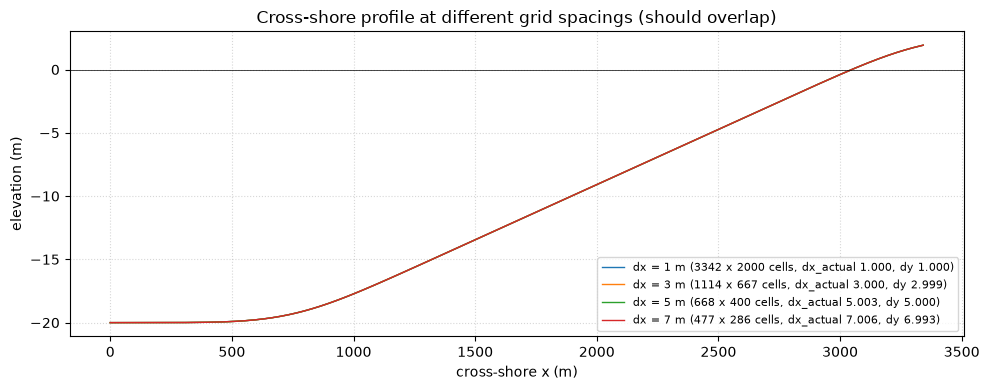

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
for dx in (1.0, 3.0, 5.0, 7.0):
    X, Y, Z = mg.bathymetry(dx)
    info = mg.grid_info(dx)
    ax.plot(X[0], Z[0], lw=1, label=f"dx = {dx:g} m ({info['nx']} x {info['ny']} cells, "
                                     f"dx_actual {info['dx_actual']:.3f}, dy {info['dy']:.3f})")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("cross-shore x (m)"); ax.set_ylabel("elevation (m)")
ax.set_title("Cross-shore profile at different grid spacings (should overlap)")
ax.legend(fontsize=8); ax.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout(); plt.show()

In [4]:
names = list(variable_ranges)
lhs = LHS(num_dimensions=len(names), seed=SEED)
lhs_data = lhs.generate(
    dimensions_names=names,
    lower_bounds=[v[0] for v in variable_ranges.values()],
    upper_bounds=[v[1] for v in variable_ranges.values()],
    num_samples=n_lhs,
)
mda = MDA(num_centers=n_subset)
mda.fit_predict(data=lhs_data[names], directional_variables=[])
subset_data = lhs_data.iloc[mda.centroid_real_indices].reset_index(drop=True).round({"tp": 2, "dx": 2})
assert len(subset_data) == n_subset
print(f"{n_subset} cases: Tp {subset_data.tp.min():.2f}-{subset_data.tp.max():.2f} s, "
      f"dx {subset_data.dx.min():.2f}-{subset_data.dx.max():.2f} m")

500 cases: Tp 4.00-15.00 s, dx 2.00-7.00 m
0 cases have Tp < 3.33 s (see warning above)


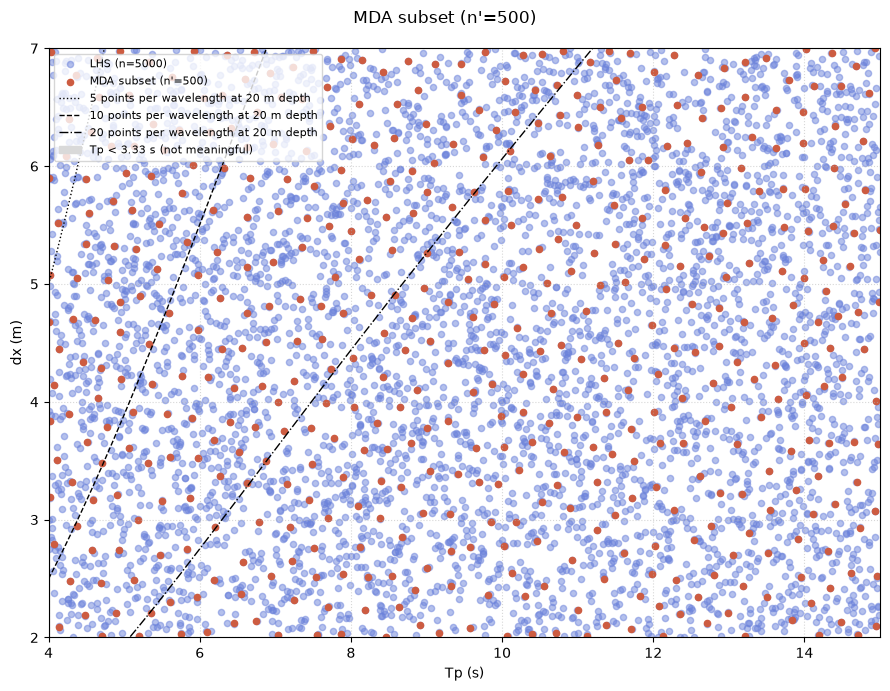

In [5]:
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(lhs_data["tp"], lhs_data["dx"], s=20, alpha=0.5, c="#6b82db", label=f"LHS (n={n_lhs})")
ax.scatter(subset_data["tp"], subset_data["dx"], s=20, c="#cd5c41", label=f"MDA subset (n'={n_subset})")

tp_line = np.linspace(variable_ranges["tp"][0], variable_ranges["tp"][1], 300)
L_off = np.array([mg.wavelength(t, mg.Z0) for t in tp_line])
for ppw, ls in [(5, ":"), (10, "--"), (20, "-.")]:
    ax.plot(tp_line, L_off / ppw, "k", ls=ls, lw=1, label=f"{ppw} points per wavelength at {mg.Z0:g} m depth")
ax.axvspan(variable_ranges["tp"][0], tp_fnyq, color="0.85", zorder=0, label=f"Tp < {tp_fnyq:.2f} s (not meaningful)")

ax.set_xlim(variable_ranges["tp"]); ax.set_ylim(variable_ranges["dx"])
ax.set_xlabel("Tp (s)"); ax.set_ylabel("dx (m)")
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="upper left", fontsize=8)
plt.suptitle(f"MDA subset (n'={n_subset})")
plt.tight_layout(); plt.show()

In [6]:
os.makedirs(base_dir, exist_ok=True)     # existing cases and results are kept
case_dirs, n_new, n_existing = [], 0, 0
for r in subset_data.itertuples():
    folder = os.path.join(base_dir, f"run_tp_{r.tp:05.2f}_dx_{r.dx:.2f}")
    case_dirs.append(folder)
    os.makedirs(folder, exist_ok=True)
    grid_path = os.path.join(folder, "grid.json")
    if not os.path.exists(grid_path):
        with open(grid_path, "w") as f:
            json.dump({"dx": float(r.dx), "output": "mean", **mg.grid_info(r.dx)}, f)
    jonswap_path = os.path.join(folder, "jonswap.txt")
    if os.path.exists(jonswap_path):
        n_existing += 1
        continue
    wave_input = f"""Hm0 = {HM0:.2f}
Tp = {r.tp:.2f}
mainang = {MAINANG:.2f}
gammajsp = 20.0
s = 16.0
fnyq = {FNYQ}
eps = 0.01         
dryslp = 1.0       
"""
    with open(jonswap_path, "w") as f:
        f.write(wave_input)
    n_new += 1

assert len(set(case_dirs)) == len(case_dirs), "two cases round to the same folder name"
with open("case_list.txt", "w") as f:          # MDA order: any first N lines are a well-spread design
    f.write("".join(f"{d}\n" for d in case_dirs))
grids = pd.DataFrame([mg.grid_info(dx) for dx in subset_data.dx])
case_params = subset_data.assign(hm0=HM0, mainang=MAINANG, s0=HM0 / (1.56 * subset_data.tp ** 2),
                                 folder=case_dirs).join(grids)
case_params.to_csv("case_parameters.csv", index=False)
print(f"{len(case_dirs)} cases: {n_new} new, {n_existing} already existed")
print("Wrote case_list.txt and case_parameters.csv")

500 cases: 500 new, 0 already existed
Wrote case_list.txt and case_parameters.csv


In [5]:
case_params = pd.read_csv("case_parameters.csv") # only if case params have already been generated

# Run time scales roughly with dx^-3 (cells ~ dx^-2, time step ~ dx), memory with dx^-2
MIN_PER_CASE_5M = 60       # surfbeat, new XBeach build (pilot: 33-34 min typical, 74 min on a slow node)
MEM_GB_5M = 4.5            # measured peak memory at 5 m (MaxRSS)
DX_BANDS = [1.0, 1.5, 2.0, 3.0, 5.0, 7.01]

def slurm_time(hours):
    h = max(1, math.ceil(hours))
    return f"{h // 24}-{h % 24:02d}:00:00" if h >= 24 else f"{h:02d}:00:00"

est_h = MIN_PER_CASE_5M / 60 * (5.0 / case_params.dx) ** 3
print(f"{'dx band (m)':>12} {'cases':>6} {'worst h/case':>13} {'node-h':>8} {'--time':>12} {'--mem':>6}")
band_cmds, total = [], 0.0
for lo, hi in zip(DX_BANDS[:-1], DX_BANDS[1:]):
    sel = (case_params.dx >= lo) & (case_params.dx < hi)
    if not sel.any():
        continue
    worst = MIN_PER_CASE_5M / 60 * (5.0 / lo) ** 3
    mem = max(16, 2 ** math.ceil(math.log2(MEM_GB_5M * (5.0 / lo) ** 2 * 1.5)))
    t_lim = slurm_time(2 * worst)
    total += est_h[sel].sum()
    print(f"{lo:5.1f} - {hi:4.1f} {sel.sum():6d} {worst:13.1f} {est_h[sel].sum():8.0f} {t_lim:>12} {mem:>5}G")
    pend = f"pending_dx{lo:g}-{min(hi, variable_ranges['dx'][1]):g}.txt"
    band_cmds.append([
        f"python post_process.py --case_list case_list.txt --write_pending {pend} --dx_min {lo:g} --dx_max {hi:g}",
        f"sbatch --time={t_lim} --mem={mem}G --array=0-$(( $(wc -l < {pend}) - 1 ))%5 xbeach_array.sbatch {pend}"])
print(f"\nTotal ~{total:,.0f} node-hours = ~{total / 5 / 24:.0f} days at 5 cases at a time, "
      f"~{total / 10 / 24:.0f} days at 10")
for write_cmd, submit_cmd in reversed(band_cmds):
    print(write_cmd)
    print(submit_cmd)
    print()

 dx band (m)  cases  worst h/case   node-h       --time  --mem
  2.0 -  3.0    103          15.6      982   1-08:00:00    64G
  3.0 -  5.0    193           4.6      433     10:00:00    32G
  5.0 -  7.0    204           1.0      123     02:00:00    16G

Total ~1,538 node-hours = ~13 days at 5 cases at a time, ~6 days at 10

Submit from a terminal in this folder (cheapest band first; test 2 cases before each band):
python post_process.py --case_list case_list.txt --write_pending pending_dx5-7.txt --dx_min 5 --dx_max 7.01
sbatch --time=02:00:00 --mem=16G --array=0-$(( $(wc -l < pending_dx5-7.txt) - 1 ))%5 xbeach_array.sbatch pending_dx5-7.txt

python post_process.py --case_list case_list.txt --write_pending pending_dx3-5.txt --dx_min 3 --dx_max 5
sbatch --time=10:00:00 --mem=32G --array=0-$(( $(wc -l < pending_dx3-5.txt) - 1 ))%5 xbeach_array.sbatch pending_dx3-5.txt

python post_process.py --case_list case_list.txt --write_pending pending_dx2-3.txt --dx_min 2 --dx_max 3
sbatch --time=1-0

In [ ]:
# collect results at any time:
#      python post_process.py --case_list case_list.txt --out q_tot_summary_sensitivity.csv